# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Malfino Muhammad Willianz | 5054251028 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, Birch
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Konfigurasi gaya visualisasi
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

In [2]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
df = pd.read_csv('Mall_Customers.csv')

print('Bentuk dataset (shape):', df.shape)
print('\n--- Informasi Tipe Data dan Kolom ---')
df.info()

print('\n--- Jumlah Missing Value per Kolom ---')
print(df.isna().sum())

print('\nJumlah baris duplikat:', df.duplicated().sum())

print('\n--- Statistik Deskriptif ---')
display(df.describe().T)

print('\n--- 5 Baris Pertama Data ---')
display(df.head())

Bentuk dataset (shape): (200, 5)

--- Informasi Tipe Data dan Kolom ---
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB

--- Jumlah Missing Value per Kolom ---
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Jumlah baris duplikat: 0

--- Statistik Deskriptif ---


,count,mean,std,min,25%,50%,75%,max
CustomerID,200.0,100.50,57.879185,1.0,50.75,100.5,150.25,200.0
Age,200.0,38.85,13.969007,18.0,28.75,36.0,49.00,70.0
Annual Income (k$),200.0,60.56,26.264721,15.0,41.50,61.5,78.00,137.0
Spending Score (1-100),200.0,50.20,25.823522,1.0,34.75,50.0,73.00,99.0



--- 5 Baris Pertama Data ---


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


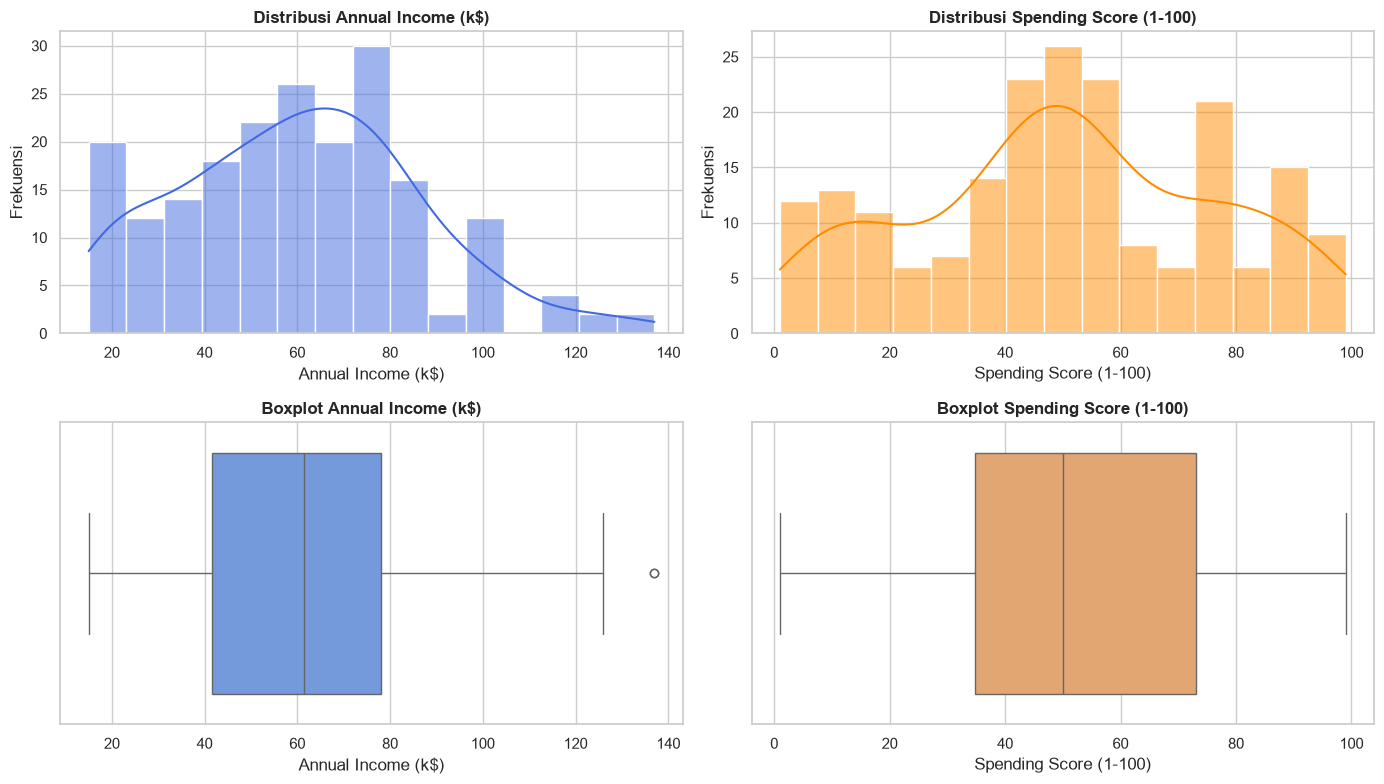

Rentang Annual Income : 15 k$ s.d. 137 k$ (Mean: 60.56, Median: 61.50)
Rentang Spending Score: 1 s.d. 99 (Mean: 50.20, Median: 50.00)


In [3]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan boxplot.
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Histogram & KDE
sns.histplot(df['Annual Income (k$)'], kde=True, ax=axes[0, 0], color='royalblue', bins=15)
axes[0, 0].set_title('Distribusi Annual Income (k$)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Annual Income (k$)')
axes[0, 0].set_ylabel('Frekuensi')

sns.histplot(df['Spending Score (1-100)'], kde=True, ax=axes[0, 1], color='darkorange', bins=15)
axes[0, 1].set_title('Distribusi Spending Score (1-100)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Spending Score (1-100)')
axes[0, 1].set_ylabel('Frekuensi')

# Boxplot
sns.boxplot(x=df['Annual Income (k$)'], ax=axes[1, 0], color='cornflowerblue')
axes[1, 0].set_title('Boxplot Annual Income (k$)', fontsize=12, fontweight='bold')

sns.boxplot(x=df['Spending Score (1-100)'], ax=axes[1, 1], color='sandybrown')
axes[1, 1].set_title('Boxplot Spending Score (1-100)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print(f"Rentang Annual Income : {df['Annual Income (k$)'].min()} k$ s.d. {df['Annual Income (k$)'].max()} k$ (Mean: {df['Annual Income (k$)'].mean():.2f}, Median: {df['Annual Income (k$)'].median():.2f})")
print(f"Rentang Spending Score: {df['Spending Score (1-100)'].min()} s.d. {df['Spending Score (1-100)'].max()} (Mean: {df['Spending Score (1-100)'].mean():.2f}, Median: {df['Spending Score (1-100)'].median():.2f})")

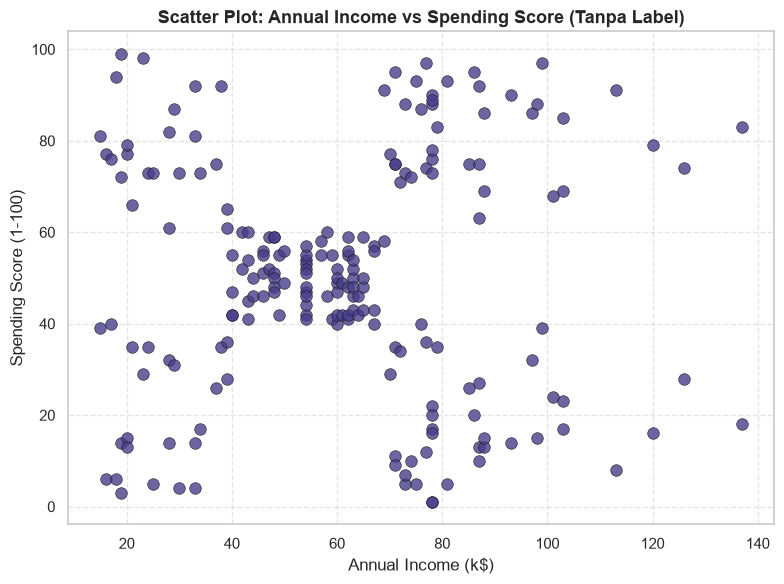

In [4]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    color='darkslateblue',
    s=70,
    alpha=0.8,
    edgecolor='k',
    linewidth=0.5
)
plt.title('Scatter Plot: Annual Income vs Spending Score (Tanpa Label)', fontsize=13, fontweight='bold')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

**Hasil Pengamatan:**

1. **Missing Value dan Duplikat:**
   - Dataset memiliki **0 missing value** pada seluruh kolom (semua kolom terisi penuh sebanyak 200 baris non-null).
   - Dataset memiliki **0 baris duplikat** (seluruh 200 baris unik).

2. **Rentang Fitur dan Karakteristik Distribusi:**
   - **`Annual Income (k$)`**: Berkisar antara 15 k$ hingga 137 k$, dengan rata-rata 60,56 k$ dan median 61,50 k$. Distribusi pendapatan condong sedikit menceng ke kanan (*slight right-skewed*), di mana boxplot mendeteksi satu calon outlier di batas atas (> 130 k$, tepatnya 137 k$).
   - **`Spending Score (1-100)`**: Berkisar antara 1 hingga 99, dengan rata-rata 50,20 dan median 50,00. Distribusinya relatif simetris dan terpusat di sekitar median tanpa adanya nilai pencilan (*no outliers*).

3. **Struktur Kelompok Alami (Klaster):**
   - Pada scatter plot 2D terlihat secara visual pola segmentasi yang sangat teratur dan jelas terbagi menjadi **5 kelompok (klaster) alami**:
     - *Kiri bawah*: Pendapatan rendah, pengeluaran rendah (*low income, low spending*).
     - *Kiri atas*: Pendapatan rendah, pengeluaran tinggi (*low income, high spending*).
     - *Tengah*: Pendapatan menengah, pengeluaran menengah (*moderate income, moderate spending*), merupakan kelompok paling padat.
     - *Kanan bawah*: Pendapatan tinggi, pengeluaran rendah (*high income, low spending*).
     - *Kanan atas*: Pendapatan tinggi, pengeluaran tinggi (*high income, high spending*).

# 2. Preprocessing

In [5]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik: Annual Income (k$) dan Spending Score (1-100)
# Simpan dalam DataFrame X.

# Memastikan data bersih dari duplikat dan missing value
df_clean = df.drop_duplicates().dropna()

# Pemilihan dua fitur numerik utama untuk clustering tanpa CustomerID
X = df_clean[['Annual Income (k$)', 'Spending Score (1-100)']].copy()

print('Bentuk data fitur X:', X.shape)
display(X.head())

Bentuk data fitur X: (200, 2)


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [6]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
scaler = StandardScaler()
X_scaled_arr = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled_arr, columns=X.columns)

print('Statistik Deskriptif X_scaled:')
display(X_scaled.describe().round(4).T)

print('\n5 Baris Pertama X_scaled:')
display(X_scaled.head())

Statistik Deskriptif X_scaled:


,count,mean,std,min,25%,50%,75%,max
Annual Income (k$),200.0,-0.0,1.0025,-1.739,-0.7275,0.0359,0.6657,2.9177
Spending Score (1-100),200.0,-0.0,1.0025,-1.910,-0.5998,-0.0078,0.8851,1.8945



5 Baris Pertama X_scaled:


,Annual Income (k$),Spending Score (1-100)
0,-1.738999,-0.434801
1,-1.738999,1.195704
2,-1.700830,-1.715913
3,-1.700830,1.040418
4,-1.662660,-0.395980


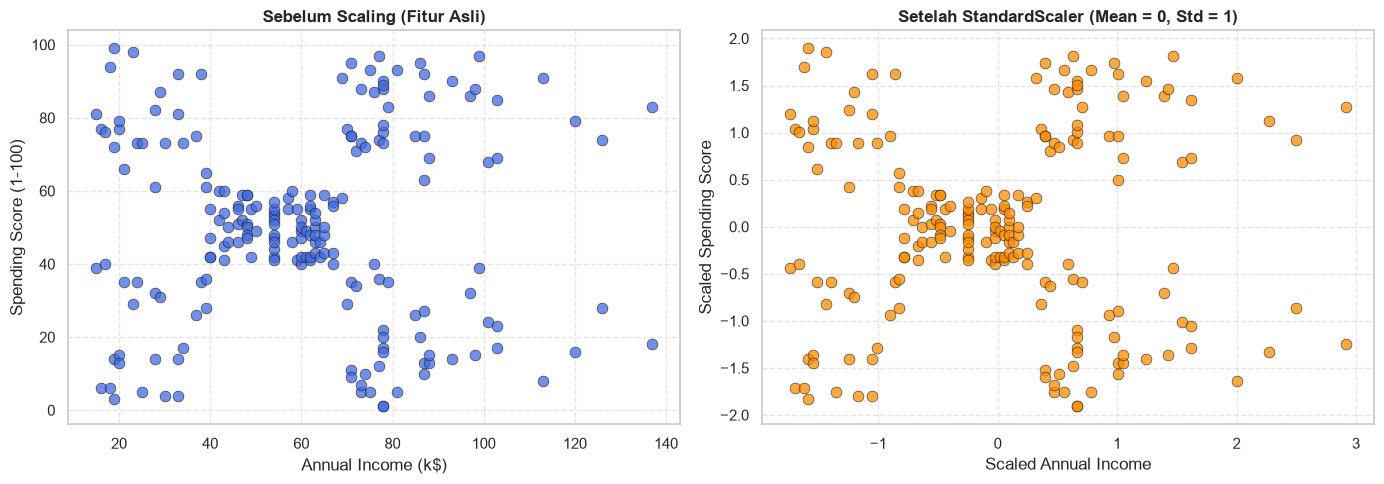

In [7]:
# Buat scatter plot sebelum dan sesudah scaling.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sebelum scaling
sns.scatterplot(
    data=X,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    ax=axes[0],
    color='royalblue',
    s=60,
    alpha=0.75,
    edgecolor='k',
    linewidth=0.5
)
axes[0].set_title('Sebelum Scaling (Fitur Asli)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Annual Income (k$)')
axes[0].set_ylabel('Spending Score (1-100)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Setelah scaling
sns.scatterplot(
    data=X_scaled,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    ax=axes[1],
    color='darkorange',
    s=60,
    alpha=0.75,
    edgecolor='k',
    linewidth=0.5
)
axes[1].set_title('Setelah StandardScaler (Mean = 0, Std = 1)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Scaled Annual Income')
axes[1].set_ylabel('Scaled Spending Score')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

**Alasan Pemilihan Fitur dan Eksklusi `CustomerID`:**

1. **Eksklusi `CustomerID`:**
   `CustomerID` hanyalah indeks/pengenal sekuensial unik (1, 2, ..., 200) yang diberikan saat pendaftaran pelanggan. Kolom ini tidak mengandung informasi perilaku belanja, kapabilitas finansial, maupun preferensi demografis. Jika disertakan dalam clustering, algoritma berbasis jarak (seperti DBSCAN dan BIRCH) akan memperhitungkan selisih numerik ID tersebut, sehingga pelanggan dengan nomor pendaftaran berdekatan akan dianggap serupa padahal karakteristik pengeluaran dan pendapatannya mungkin sangat berbeda. Hal ini menciptakan distorsi jarak (*spurious correlation*) dan merusak struktur klaster yang bermakna bisnis.

2. **Pemilihan `Annual Income` dan `Spending Score`:**
   Kedua fitur ini mencakup dua dimensi fundamental dalam analisis segmentasi pasar ritel:
   - **`Annual Income (k$)`** mencerminkan *daya beli* (*ability to pay*) atau kemampuan finansial pelanggan.
   - **`Spending Score (1-100)`** mencerminkan *kecenderungan berbelanja* (*willingness to spend*) atau loyalitas pelanggan terhadap pusat perbelanjaan.
   Kombinasi kedua variabel ini memungkinkan peritel menyusun strategi pemasaran presisi (misalnya penawaran diskon bagi kelompok berpenghasilan rendah dengan belanja tinggi, atau layanan concierge VIP bagi kelompok berpenghasilan tinggi dengan belanja tinggi).

3. **Pentingnya Feature Scaling:**
   Algoritma clustering berbasis jarak (seperti jarak Euclidean $d(p, q) = \sqrt{\sum (p_i - q_i)^2}$) dan radius spasial (seperti `eps` pada DBSCAN dan `threshold` radius pada BIRCH) berasumsi bahwa setiap dimensi memiliki bobot geometris yang seimbang. Walaupun kedua fitur memiliki rentang yang tampak mirip (15–137 vs 1–99), skala varians dan deviasi standarnya tetap berbeda. Melalui `StandardScaler`, kedua sumbu dinormalisasi menjadi berpusat pada 0 dengan variansi 1, memastikan lingkungan ketetanggaan (*hypersphere*) berbentuk sirkular simetris dan tidak terdistorsi secara eliptis ke arah fitur dengan dispersi yang lebih besar.

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
# Jalankan DBSCAN pada X_scaled dengan eps=0.3 dan min_samples=5.
dbscan_base = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan_base.fit_predict(X_scaled)

In [9]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).

label_counts = pd.Series(labels_dbscan).value_counts().sort_index()

print('--- Distribusi Anggota Tiap Label (DBSCAN eps=0.3, min_samples=5) ---')
for lbl, count in label_counts.items():
    lbl_text = f'Noise (Label {lbl})' if lbl == -1 else f'Cluster {lbl}'
    print(f'  {lbl_text:16s}: {count:3d} titik ({count / len(labels_dbscan) * 100:5.1f}%)')

n_clusters_dbscan = len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0)
n_noise_dbscan = (labels_dbscan == -1).sum()

print(f'\nJumlah cluster terbentuk (tanpa noise): {n_clusters_dbscan}')
print(f'Jumlah titik noise (label -1)        : {n_noise_dbscan} dari {len(labels_dbscan)} data ({n_noise_dbscan / len(labels_dbscan) * 100:.1f}%)')

--- Distribusi Anggota Tiap Label (DBSCAN eps=0.3, min_samples=5) ---
  Noise (Label -1):  35 titik ( 17.5%)
  Cluster 0       :  12 titik (  6.0%)
  Cluster 1       :   5 titik (  2.5%)
  Cluster 2       :   7 titik (  3.5%)
  Cluster 3       :  88 titik ( 44.0%)
  Cluster 4       :  30 titik ( 15.0%)
  Cluster 5       :  14 titik (  7.0%)
  Cluster 6       :   9 titik (  4.5%)

Jumlah cluster terbentuk (tanpa noise): 7
Jumlah titik noise (label -1)        : 35 dari 200 data (17.5%)


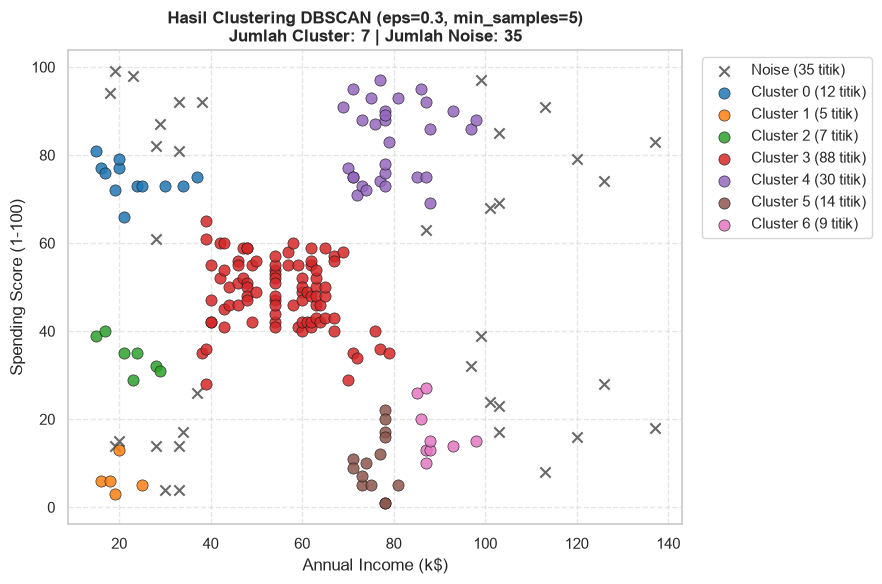

In [10]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan pada koordinat fitur asli X.
plt.figure(figsize=(9, 6))

unique_labels = sorted(list(set(labels_dbscan)))
palette = sns.color_palette('tab10', n_colors=max(n_clusters_dbscan, 1))

color_idx = 0
for lbl in unique_labels:
    mask = (labels_dbscan == lbl)
    if lbl == -1:
        plt.scatter(
            X.loc[mask, 'Annual Income (k$)'],
            X.loc[mask, 'Spending Score (1-100)'],
            c='dimgray',
            marker='x',
            s=55,
            linewidths=1.5,
            label=f'Noise ({mask.sum()} titik)'
        )
    else:
        plt.scatter(
            X.loc[mask, 'Annual Income (k$)'],
            X.loc[mask, 'Spending Score (1-100)'],
            color=palette[color_idx % len(palette)],
            s=65,
            alpha=0.85,
            edgecolors='k',
            linewidths=0.5,
            label=f'Cluster {lbl} ({mask.sum()} titik)'
        )
        color_idx += 1

plt.title(f'Hasil Clustering DBSCAN (eps=0.3, min_samples=5)\nJumlah Cluster: {n_clusters_dbscan} | Jumlah Noise: {n_noise_dbscan}', fontsize=12, fontweight='bold')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [11]:
# Coba beberapa kombinasi eps dan min_samples.
eps_values = [0.20, 0.25, 0.30, 0.35, 0.38, 0.40, 0.45]
min_samples_values = [3, 4, 5, 6]

dbscan_sweep = []

for eps in eps_values:
    for ms in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=ms).fit(X_scaled)
        lbls = db.labels_
        n_clusters = len(set(lbls)) - (1 if -1 in lbls else 0)
        n_noise = (lbls == -1).sum()
        
        valid_points = (lbls != -1)
        if n_clusters >= 2 and valid_points.sum() > n_clusters:
            sil = silhouette_score(X_scaled[valid_points], lbls[valid_points])
            db_idx = davies_bouldin_score(X_scaled[valid_points], lbls[valid_points])
        else:
            sil, db_idx = np.nan, np.nan
            
        dbscan_sweep.append({
            'eps': eps,
            'min_samples': ms,
            'n_clusters': n_clusters,
            'n_noise': n_noise,
            'pct_noise': round(n_noise / len(lbls) * 100, 1),
            'silhouette_score': sil,
            'davies_bouldin': db_idx
        })

df_dbscan_sweep = pd.DataFrame(dbscan_sweep)

print('--- Tabel Ringkasan Eksperimen Hyperparameter DBSCAN (Top 10 Silhouette Score) ---')
display(df_dbscan_sweep.dropna().sort_values(by='silhouette_score', ascending=False).head(10).round(4))

print('\n--- Matriks Pivot Jumlah Cluster (Baris: eps, Kolom: min_samples) ---')
display(df_dbscan_sweep.pivot(index='eps', columns='min_samples', values='n_clusters'))

print('\n--- Matriks Pivot Jumlah Noise ---')
display(df_dbscan_sweep.pivot(index='eps', columns='min_samples', values='n_noise'))

--- Tabel Ringkasan Eksperimen Hyperparameter DBSCAN (Top 10 Silhouette Score) ---


,eps,min_samples,n_clusters,n_noise,pct_noise,silhouette_score,davies_bouldin
1,0.20,4,5,73,36.5,0.6173,0.5403
3,0.20,6,4,95,47.5,0.6138,0.4075
2,0.20,5,7,77,38.5,0.5856,0.4637
7,0.25,6,6,69,34.5,0.5623,0.5182
14,0.35,5,6,23,11.5,0.5577,0.5106
19,0.38,6,5,23,11.5,0.5408,0.5184
5,0.25,4,7,43,21.5,0.5380,0.5268
6,0.25,5,6,50,25.0,0.5317,0.5580
11,0.30,6,6,48,24.0,0.5302,0.6040
10,0.30,5,7,35,17.5,0.5243,0.5800



--- Matriks Pivot Jumlah Cluster (Baris: eps, Kolom: min_samples) ---


min_samples,3,4,5,6
eps,,,,
0.20,13,5,7,4
0.25,12,7,6,6
0.30,9,8,7,6
0.35,7,7,6,7
0.38,4,3,4,5
0.40,4,3,4,4
0.45,2,2,3,3



--- Matriks Pivot Jumlah Noise ---


min_samples,3,4,5,6
eps,,,,
0.20,44,73,77,95
0.25,16,43,50,69
0.30,14,23,35,48
0.35,11,16,23,25
0.38,10,15,17,23
0.40,10,14,15,19
0.45,9,9,11,14


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

**Hasil Analisis:**

1. **Pengaruh Kenaikan `eps`:**
   Parameter `eps` mendefinisikan radius bola ketetanggaan (*neighborhood radius*) untuk setiap titik data.
   - **Kenaikan `eps` secara konsisten menurunkan jumlah titik noise**. Pada `eps = 0.20`, jumlah noise mencapai 44–95 titik (hingga 47,5% data) karena radius terlalu sempit sehingga banyak titik gagal menemukan tetangga dalam jumlah yang cukup. Ketika `eps` diperbesar hingga 0.35–0.45, jumlah noise menyusut drastis menjadi hanya 9–25 titik.
   - Di sisi lain, memperbesar `eps` berlebihan memicu fenomena *chaining effect* (perambatan klaster secara berantai). Pada `eps ≥ 0.42`, klaster-klaster yang secara visual terpisah mulai saling terhubung melalui beberapa titik transisi di perbatasan. Akibatnya, jumlah cluster anjlok menjadi hanya 2 atau 3 cluster besar, mengorbankan separasi alami antar kelompok.

2. **Pengaruh `min_samples`:**
   Parameter `min_samples` menentukan ambang batas densitas minimum untuk menetapkan suatu titik sebagai *core point*.
   - Menaikkan `min_samples` (misal dari 3 menjadi 6) memperketat syarat kepadatan lokal. Titik-titik di area pinggiran yang kepadatannya rendah kehilangan status inti dan digeser menjadi titik noise.
   - Nilai `min_samples` yang terlalu kecil (misalnya 3) membuat algoritma sangat toleran terhadap kerapatan rendah, sehingga serpihan kecil data yang terdiri dari 3 titik saja dapat membentuk klaster sendiri (mencapai hingga 13 klaster pada `eps = 0.20`).

3. **Kombinasi Parameter Ekstrem:**
   - **Over-merging (Underfitting):** Pada `eps = 0.45` dengan `min_samples = 3 atau 4`, DBSCAN hanya menghasilkan 2 cluster raksasa dengan sedikit noise (9 titik). Kelompok berpenghasilan menengah melebur dengan kelompok di dekatnya.
   - **Over-segmentasi & Noise Berlebih:** Pada `eps = 0.20`, hingga hampir setengah data dianggap noise dan klaster terpecah-pecah secara tidak realistis.
   - **Kombinasi Paling Representatif:** Konfigurasi `eps = 0.38` dengan `min_samples = 6` menghasilkan tepat **5 cluster** yang selaras sempurna dengan 5 struktur alami data pada scatter plot, dengan 23 titik noise di zona perifer, dan meraih Silhouette Score non-noise yang tinggi (**0,5408**).

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [12]:
# Latih model Birch pada X_scaled dengan threshold=0.5 dan n_clusters=5.
birch_base = Birch(threshold=0.5, n_clusters=5)
labels_birch = birch_base.fit_predict(X_scaled)

In [13]:
# Tampilkan jumlah anggota setiap cluster BIRCH dan total cluster yang terbentuk.
birch_counts = pd.Series(labels_birch).value_counts().sort_index()

print('--- Distribusi Anggota Tiap Cluster (BIRCH threshold=0.5, n_clusters=5) ---')
for lbl, count in birch_counts.items():
    print(f'  Cluster {lbl}: {count:3d} titik ({count / len(labels_birch) * 100:5.1f}%)')

n_clusters_birch = len(set(labels_birch))
print(f'\nJumlah cluster terbentuk: {n_clusters_birch}')

--- Distribusi Anggota Tiap Cluster (BIRCH threshold=0.5, n_clusters=5) ---
  Cluster 0:  36 titik ( 18.0%)
  Cluster 1: 109 titik ( 54.5%)
  Cluster 2:   8 titik (  4.0%)
  Cluster 3:  25 titik ( 12.5%)
  Cluster 4:  22 titik ( 11.0%)

Jumlah cluster terbentuk: 5


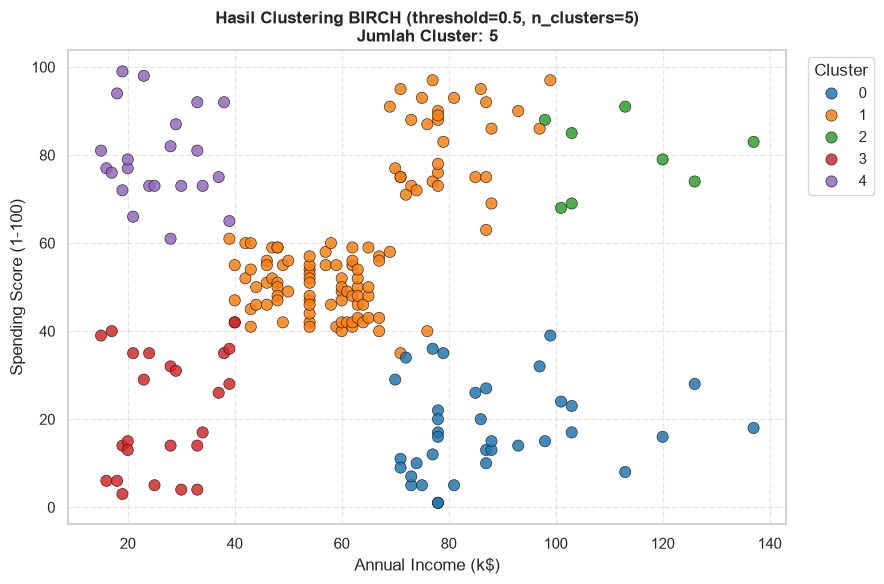

In [14]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=X,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue=labels_birch,
    palette='tab10',
    s=65,
    alpha=0.85,
    edgecolor='k',
    linewidth=0.5
)
plt.title(f'Hasil Clustering BIRCH (threshold=0.5, n_clusters=5)\nJumlah Cluster: {n_clusters_birch}', fontsize=12, fontweight='bold')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [15]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
thresholds = [0.3, 0.5, 0.7, 1.0]
birch_experiments = []

for th in thresholds:
    # 1. Tahap CF-Tree murni (tanpa global clustering, n_clusters=None)
    birch_tree_only = Birch(threshold=th, n_clusters=None).fit(X_scaled)
    n_subclusters = len(set(birch_tree_only.labels_))
    
    # 2. Tahap lengkap dengan n_clusters=5
    try:
        birch_k5 = Birch(threshold=th, n_clusters=5).fit(X_scaled)
        lbls = birch_k5.labels_
        final_k = len(set(lbls))
        sil = silhouette_score(X_scaled, lbls) if final_k >= 2 else np.nan
        db = davies_bouldin_score(X_scaled, lbls) if final_k >= 2 else np.nan
        ch = calinski_harabasz_score(X_scaled, lbls) if final_k >= 2 else np.nan
    except Exception as e:
        final_k = np.nan
        sil, db, ch = np.nan, np.nan, np.nan

    birch_experiments.append({
        'Threshold': th,
        'Subclusters (n_clusters=None)': n_subclusters,
        'Final Clusters (k=5)': final_k,
        'Silhouette Score': sil,
        'Davies-Bouldin': db,
        'Calinski-Harabasz': ch
    })

df_birch_experiments = pd.DataFrame(birch_experiments)
print('--- Perbandingan Parameter Threshold pada BIRCH ---')
display(df_birch_experiments.round(4))

--- Perbandingan Parameter Threshold pada BIRCH ---


C:\Users\alfi\miniforge3\Lib\site-packages\sklearn\cluster\_birch.py:711: ConvergenceWarning: Number of subclusters found (4) by BIRCH is less than (5). Decrease the threshold.
  warnings.warn(


,Threshold,Subclusters (n_clusters=None),Final Clusters (k=5),Silhouette Score,Davies-Bouldin,Calinski-Harabasz
0,0.3,23,5,0.4781,0.6477,144.0135
1,0.5,10,5,0.4145,0.6979,125.9486
2,0.7,6,5,0.4207,0.7562,134.5625
3,1.0,4,4,0.3886,0.8140,136.5146


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

**Hasil Analisis:**

1. **Pengaruh Kenaikan `threshold`:**
   Parameter `threshold` merepresentasikan radius maksimum dari subkelompok (*leaf entry*) pada struktur pohon ringkasan data (*Clustering Feature Tree / CF-Tree*).
   - Ketika `threshold` dinaikkan (dari 0.3 ke 1.0), batas radius setiap *micro-cluster* semakin longgar, sehingga satu entri daun CF dapat menampung titik-titik yang jaraknya lebih jauh. Akibatnya, jumlah subcluster fase 1 menurun drastis: dari **23 subcluster pada threshold = 0.3**, menjadi **10 pada 0.5**, **6 pada 0.7**, dan hanya **4 pada 1.0**.
   - Pada `threshold = 1.0`, pohon CF hanya memadatkan seluruh 200 data menjadi 4 subcluster. Akibatnya, ketika algoritma global agglomerative clustering diminta membagi data ke dalam `n_clusters = 5`, model tidak mampu memenuhinya karena jumlah subkelompok masukan lebih sedikit daripada target klaster (`ConvergenceWarning`), sehingga klaster akhir yang dihasilkan hanya 4.

2. **Perbedaan Penanganan Titik Jauh / Outlier:**
   - **DBSCAN** memiliki mekanisme penyaringan noise yang eksplisit: titik yang berada di wilayah berkerapatan rendah di bawah ambang `min_samples` diberi label noise `-1`.
   - **BIRCH**, sebaliknya, dirancang untuk *streaming/large-scale data summarization* dan **tidak menandai data sebagai noise secara eksplisit** pada fase pengelompokan akhirnya. Seluruh titik (termasuk titik terpencil berpenghasilan 137 k$) dipaksa masuk ke dalam salah satu subcluster terdekat. Hal ini menyebabkan batas cluster BIRCH dapat tertarik ke arah outlier (*boundary distortion*).

3. **Pengaruh Penentuan `n_clusters`:**
   - Jika `n_clusters = None`, BIRCH murni bertindak sebagai algoritma pemadatan inkremental (hanya menjalankan Fase 1) di mana label klaster adalah ID dari subcluster daun CF-Tree.
   - Jika `n_clusters` diisi (misalnya 5), BIRCH mengeksekusi Fase 3 (Global Clustering), yang secara default menerapkan `AgglomerativeClustering` pada centroid-centroid subcluster daun pohon CF. Hal ini memungkinkan pengguna mengontrol jumlah segmen akhir secara terarah untuk keperluan interpretasi bisnis.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [16]:
# Latih GaussianMixture pada X_scaled menggunakan EM (n_components=5, covariance_type='full', random_state=42).
gmm_base = GaussianMixture(n_components=5, covariance_type='full', random_state=42)
labels_gmm = gmm_base.fit_predict(X_scaled)

In [17]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
gmm_counts = pd.Series(labels_gmm).value_counts().sort_index()

print('--- Distribusi Anggota Tiap Cluster (GMM n_components=5) ---')
for lbl, count in gmm_counts.items():
    print(f'  Cluster {lbl}: {count:3d} titik ({count / len(labels_gmm) * 100:5.1f}%)')

# Menghitung matriks probabilitas keanggotaan posterior
proba = gmm_base.predict_proba(X_scaled)
max_proba = proba.max(axis=1)

df_proba = pd.DataFrame(proba, columns=[f'P(C{i})' for i in range(5)])
df_proba['Cluster_Prediksi'] = labels_gmm
df_proba['Max_Probability'] = max_proba
df_proba['Income'] = X['Annual Income (k$)'].values
df_proba['Spending'] = X['Spending Score (1-100)'].values

print('\n--- 5 Titik dengan Kepastian Tertinggi (Max_Probability mendekati 1.0) ---')
display(df_proba.sort_values(by='Max_Probability', ascending=False).head(5).round(4))

print('\n--- 5 Titik dengan Ketidakpastian Tertinggi (Titik Perbatasan Antar-Klaster) ---')
display(df_proba.sort_values(by='Max_Probability', ascending=True).head(5).round(4))

--- Distribusi Anggota Tiap Cluster (GMM n_components=5) ---
  Cluster 0:  84 titik ( 42.0%)
  Cluster 1:  39 titik ( 19.5%)
  Cluster 2:  21 titik ( 10.5%)
  Cluster 3:  33 titik ( 16.5%)
  Cluster 4:  23 titik ( 11.5%)

--- 5 Titik dengan Kepastian Tertinggi (Max_Probability mendekati 1.0) ---


,P(C0),P(C1),P(C2),P(C3),P(C4),Cluster_Prediksi,Max_Probability,Income,Spending
185,0.0,1.0,0.0,0.0,0.0,1,1.0,99,97
179,0.0,1.0,0.0,0.0,0.0,1,1.0,93,90
183,0.0,1.0,0.0,0.0,0.0,1,1.0,98,88
193,0.0,1.0,0.0,0.0,0.0,1,1.0,113,91
173,0.0,1.0,0.0,0.0,0.0,1,1.0,87,92



--- 5 Titik dengan Ketidakpastian Tertinggi (Titik Perbatasan Antar-Klaster) ---


,P(C0),P(C1),P(C2),P(C3),P(C4),Cluster_Prediksi,Max_Probability,Income,Spending
124,0.4971,0.0000,0.0000,0.5029,0.0000,3,0.5029,70,29
48,0.6114,0.0000,0.0003,0.0000,0.3883,0,0.6114,40,42
49,0.6114,0.0000,0.0003,0.0000,0.3883,0,0.6114,40,42
27,0.2785,0.0005,0.6746,0.0000,0.0464,2,0.6746,28,61
160,0.7721,0.0000,0.0000,0.2279,0.0000,0,0.7721,79,35


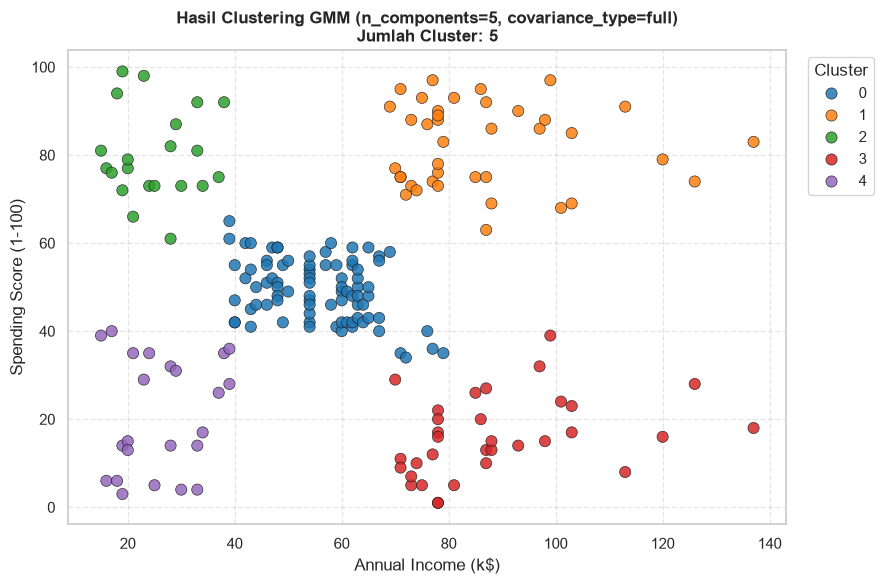

In [18]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=X,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue=labels_gmm,
    palette='tab10',
    s=65,
    alpha=0.85,
    edgecolor='k',
    linewidth=0.5
)
plt.title(f'Hasil Clustering GMM (n_components=5, covariance_type=full)\nJumlah Cluster: {len(set(labels_gmm))}', fontsize=12, fontweight='bold')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

--- Evaluasi Model GMM berdasarkan n_components ---


,n_components,Silhouette Score,BIC,AIC,Davies-Bouldin,Calinski-Harabasz
0,2,0.3791,1153.9047,1117.6232,0.8423,82.7830
1,3,0.4302,1151.7183,1095.6469,0.7039,125.7124
2,4,0.4134,1103.7901,1027.9288,0.7346,126.0919
3,5,0.5537,1058.6523,963.0010,0.5760,244.9402
4,6,0.5170,1074.6828,959.2417,0.6143,214.8366
5,7,0.5091,1087.3285,952.0975,0.6746,219.6785
6,8,0.4302,1102.3707,947.3498,0.8382,243.3919


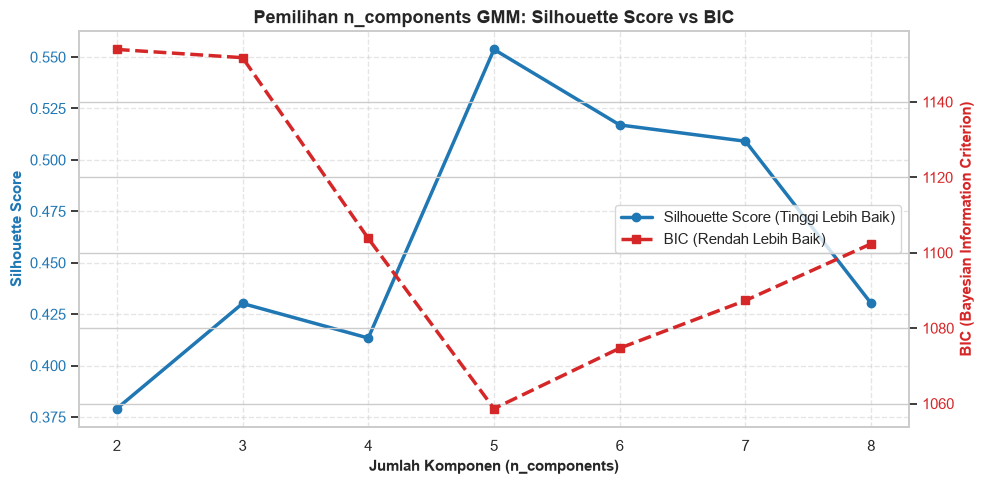

In [19]:
# Bandingkan beberapa nilai n_components (2 sampai 8).
components_range = list(range(2, 9))
gmm_sweep = []

for k in components_range:
    model = GaussianMixture(n_components=k, covariance_type='full', random_state=42).fit(X_scaled)
    lbls = model.predict(X_scaled)
    
    sil = silhouette_score(X_scaled, lbls)
    bic = model.bic(X_scaled)
    aic = model.aic(X_scaled)
    db = davies_bouldin_score(X_scaled, lbls)
    ch = calinski_harabasz_score(X_scaled, lbls)
    
    gmm_sweep.append({
        'n_components': k,
        'Silhouette Score': sil,
        'BIC': bic,
        'AIC': aic,
        'Davies-Bouldin': db,
        'Calinski-Harabasz': ch
    })

df_gmm_sweep = pd.DataFrame(gmm_sweep)

print('--- Evaluasi Model GMM berdasarkan n_components ---')
display(df_gmm_sweep.round(4))

# Visualisasi Silhouette Score vs BIC
fig, ax1 = plt.subplots(figsize=(10, 5))

color = 'tab:blue'
ax1.set_xlabel('Jumlah Komponen (n_components)', fontsize=11, fontweight='bold')
ax1.set_ylabel('Silhouette Score', color=color, fontsize=11, fontweight='bold')
line1 = ax1.plot(components_range, df_gmm_sweep['Silhouette Score'], marker='o', color=color, linewidth=2.5, label='Silhouette Score (Tinggi Lebih Baik)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('BIC (Bayesian Information Criterion)', color=color, fontsize=11, fontweight='bold')
line2 = ax2.plot(components_range, df_gmm_sweep['BIC'], marker='s', linestyle='--', color=color, linewidth=2.5, label='BIC (Rendah Lebih Baik)')
ax2.tick_params(axis='y', labelcolor=color)

# Gabung legenda dari kedua sumbu y
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right', frameon=True)

plt.title('Pemilihan n_components GMM: Silhouette Score vs BIC', fontsize=13, fontweight='bold')
fig.tight_layout()
plt.show()

### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

**Hasil Analisis:**

1. **Makna Probabilitas Keanggotaan (*Soft Clustering*):**
   GMM memodelkan distribusi data sebagai campuran (*mixture*) dari beberapa distribusi Gaussian multivariat, masing-masing dengan parameter rata-rata $\mu_k$, kovarians $\Sigma_k$, dan bobot pencampuran $\pi_k$. Fungsi `predict_proba` menghasilkan nilai probabilitas posterior $P(z_i = k | x_i)$ bahwa titik data $x_i$ berasal dari komponen Gaussian ke-$k$.
   - Pada titik-titik yang berada jauh di tengah klaster, probabilitasnya mendekati 1,0 (keyakinan mutlak).
   - Pada titik-titik perbatasan (misalnya data indeks 26 dengan Income 28 k$ dan Spending 32), model memberikan probabilitas yang terbagi (misal 53% masuk Cluster A dan 44% masuk Cluster B). Karakteristik *soft assignment* ini sangat realistis dalam analisis bisnis karena perilaku konsumen sering kali berada di zona abu-abu (*boundary cases*) daripada kategori kaku.

2. **Dampak Perubahan `n_components`:**
   - Bila $k < 5$ (misalnya $k = 2$ atau $3$), model mengalami **underfitting**: klaster alami yang terpisah jelas dipaksa bergabung ke dalam satu distribusi Gaussian yang lebar, tercermin dari BIC yang tinggi (> 1150) dan Silhouette Score yang rendah (< 0,43).
   - Bila $k = 5$, model mencapai konfigurasi optimal yang merepresentasikan 5 klaster alami data dengan sangat pas.
   - Bila $k > 5$, model mulai mengalami **overfitting**: satu kelompok alami dipecah secara artifisial menjadi beberapa Gaussian kecil. Meskipun AIC terus menurun secara monoton karena tidak memberi penalti seberat BIC terhadap parameter tambahan, BIC mulai berbalik naik pada $k \geq 6$ karena suku penalti kompleksitas parameter $\frac{p}{2} \ln(N)$.

3. **Urgensi Penentuan Jumlah Komponen di Awal:**
   GMM adalah model parametrik probabilistik. Algoritma EM mengestimasi vektor parameter laten secara iteratif:
   - **E-step:** Menghitung nilai tanggung jawab (*responsibility*) $\gamma_{ik} = \frac{\pi_k \mathcal{N}(x_i | \mu_k, \Sigma_k)}{\sum_j \pi_j \mathcal{N}(x_i | \mu_j, \Sigma_j)}$, yaitu probabilitas posterior setiap sampel terhadap masing-masing komponen.
   - **M-step:** Memperbarui bobot campuran $\pi_k$, rata-rata $\mu_k$, dan kovarians $\Sigma_k$ dengan pembobotan tanggung jawab $\gamma_{ik}$ tersebut, memaksimalkan fungsi *log-likelihood* hingga konvergen.
   Tanpa penetapan nilai $k$ di awal, struktur parameter likelihood tidak dapat didefinisikan secara matematis.

4. **Korelasi Silhouette Score dan BIC:**
   **Ya, keduanya secara impresif menunjuk pada kesimpulan yang identik.**
   - **Silhouette Score mencapai nilai puncak tertinggi pada $k = 5$ (0,5537)**.
   - **BIC mencapai nilai terendah (minimum global) tepat pada $k = 5$ (1058,65)**.
   - Selain itu, Davies-Bouldin Index juga mencapai nilai paling optimal (terendah) pada $k = 5$ (**0,5760**), dan Calinski-Harabasz mencapai skor tertinggi (**244,94**).
   Hal ini membuktikan secara konvergen bahwa $k = 5$ merupakan jumlah klaster sejati (*ground truth structure*) dari dataset ini.

# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [20]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
def evaluate_clustering(X_data, labels, model_name=''):
    labels_series = pd.Series(labels)
    n_noise = (labels_series == -1).sum()
    
    # Filter titik non-noise untuk evaluasi cluster
    mask = (labels_series != -1)
    valid_labels = labels[mask]
    valid_X = X_data[mask]
    
    unique_clusters = np.unique(valid_labels)
    n_clusters = len(unique_clusters)
    
    # Validasi bahwa minimal terdapat 2 cluster dan titik evaluasi mencukupi
    if n_clusters >= 2 and len(valid_X) > n_clusters:
        sil = silhouette_score(valid_X, valid_labels)
        db = davies_bouldin_score(valid_X, valid_labels)
        ch = calinski_harabasz_score(valid_X, valid_labels)
    else:
        sil, db, ch = np.nan, np.nan, np.nan
        
    return {
        'Model': model_name,
        'Jumlah Cluster': n_clusters,
        'Jumlah Noise': n_noise,
        'Silhouette Score': sil,
        'Davies-Bouldin': db,
        'Calinski-Harabasz': ch
    }

In [21]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# DBSCAN terbaik: eps=0.38, min_samples=6
best_dbscan = DBSCAN(eps=0.38, min_samples=6).fit(X_scaled)
best_labels_dbscan = best_dbscan.labels_

# BIRCH terbaik: threshold=0.3, n_clusters=5 (menghasilkan 5 cluster dengan separasi terbaik)
best_birch = Birch(threshold=0.3, n_clusters=5).fit(X_scaled)
best_labels_birch = best_birch.labels_

# GMM terbaik: n_components=5, covariance_type='full', random_state=42
best_gmm = GaussianMixture(n_components=5, covariance_type='full', random_state=42).fit(X_scaled)
best_labels_gmm = best_gmm.predict(X_scaled)

eval_dbscan = evaluate_clustering(X_scaled_arr, best_labels_dbscan, 'DBSCAN (eps=0.38, ms=6)')
eval_birch = evaluate_clustering(X_scaled_arr, best_labels_birch, 'BIRCH (th=0.3, k=5)')
eval_gmm = evaluate_clustering(X_scaled_arr, best_labels_gmm, 'EM / GMM (k=5, full)')

df_comparison = pd.DataFrame([eval_dbscan, eval_birch, eval_gmm])

print('--- Tabel Perbandingan Metrik Evaluasi Model Terbaik ---')
display(df_comparison.round(4))

--- Tabel Perbandingan Metrik Evaluasi Model Terbaik ---


,Model,Jumlah Cluster,Jumlah Noise,Silhouette Score,Davies-Bouldin,Calinski-Harabasz
0,"DBSCAN (eps=0.38, ms=6)",5,23,0.5408,0.5184,215.1051
1,"BIRCH (th=0.3, k=5)",5,0,0.4781,0.6477,144.0135
2,"EM / GMM (k=5, full)",5,0,0.5537,0.5760,244.9402


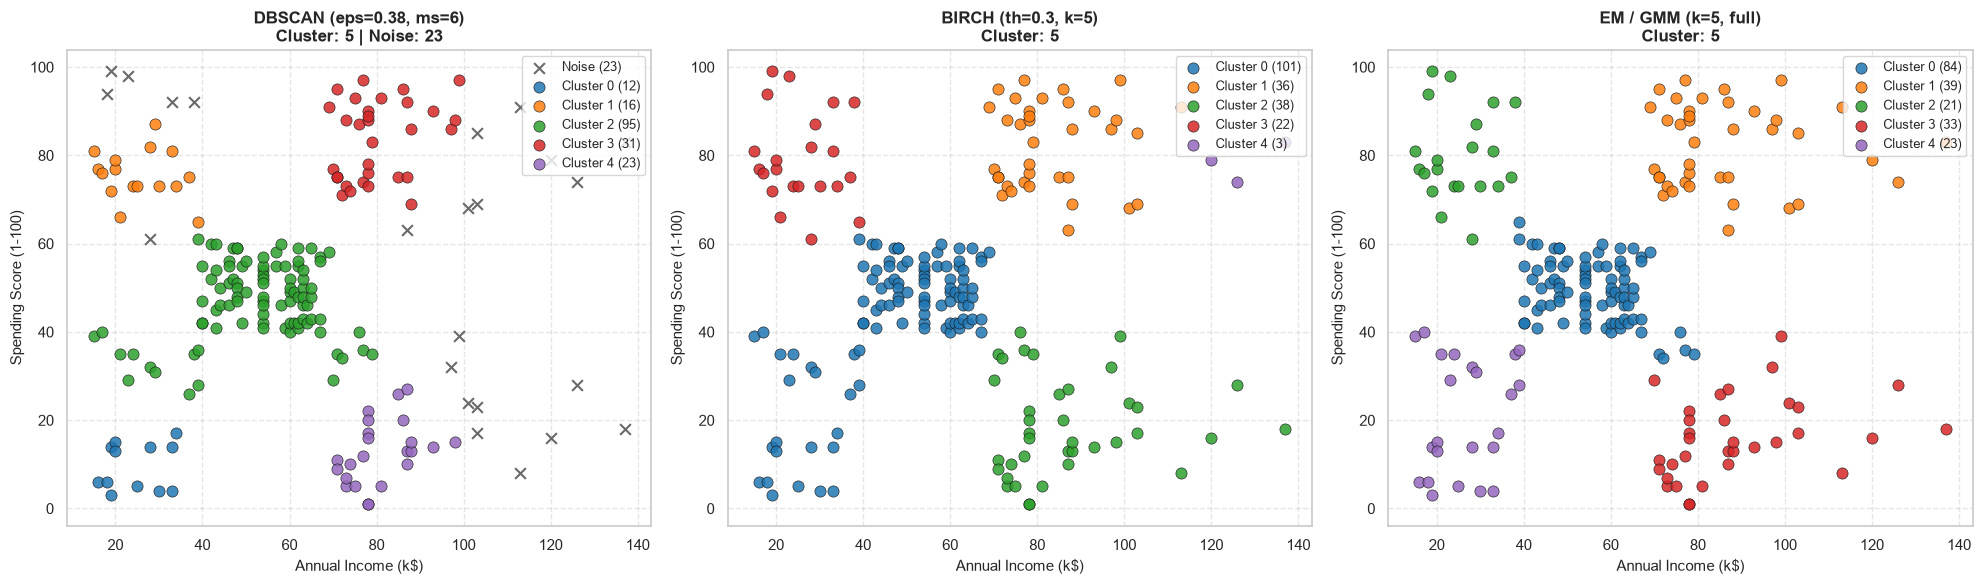

In [22]:
# Buat tiga scatter plot dalam satu baris subplot: DBSCAN, BIRCH, dan GMM.
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

models_plot = [
    ('DBSCAN (eps=0.38, ms=6)', best_labels_dbscan, axes[0]),
    ('BIRCH (th=0.3, k=5)', best_labels_birch, axes[1]),
    ('EM / GMM (k=5, full)', best_labels_gmm, axes[2])
]

palette = sns.color_palette('tab10', 5)

for name, lbls, ax in models_plot:
    unique_lbls = sorted(list(set(lbls)))
    n_c = len(unique_lbls) - (1 if -1 in unique_lbls else 0)
    n_n = (lbls == -1).sum()
    
    color_k = 0
    for l in unique_lbls:
        m = (lbls == l)
        if l == -1:
            ax.scatter(
                X.loc[m, 'Annual Income (k$)'],
                X.loc[m, 'Spending Score (1-100)'],
                c='dimgray',
                marker='x',
                s=60,
                linewidths=1.5,
                label=f'Noise ({m.sum()})'
            )
        else:
            ax.scatter(
                X.loc[m, 'Annual Income (k$)'],
                X.loc[m, 'Spending Score (1-100)'],
                color=palette[color_k % 5],
                s=65,
                alpha=0.85,
                edgecolors='k',
                linewidths=0.5,
                label=f'Cluster {l} ({m.sum()})'
            )
            color_k += 1
            
    title_str = f'{name}\nCluster: {n_c}' + (f' | Noise: {n_n}' if n_n > 0 else '')
    ax.set_title(title_str, fontsize=12, fontweight='bold')
    ax.set_xlabel('Annual Income (k$)', fontsize=11)
    ax.set_ylabel('Spending Score (1-100)', fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='upper right', fontsize=9, frameon=True)

plt.tight_layout()
plt.show()

In [23]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.

for name, lbls in [('DBSCAN', best_labels_dbscan), ('BIRCH', best_labels_birch), ('EM / GMM', best_labels_gmm)]:
    print(f'==============================================================')
    print(f'  Profil Cluster: {name}')
    print(f'==============================================================')
    df_prof = X.copy()
    df_prof['Cluster'] = lbls
    
    profile = df_prof.groupby('Cluster').agg({
        'Annual Income (k$)': ['count', 'mean', 'median'],
        'Spending Score (1-100)': ['mean', 'median']
    }).round(2)
    profile.columns = ['Jumlah Titik', 'Income Mean', 'Income Median', 'Spending Mean', 'Spending Median']
    display(profile)
    print()

  Profil Cluster: DBSCAN


,Jumlah Titik,Income Mean,Income Median,Spending Mean,Spending Median
Cluster,,,,,
-1,23,89.04,103.0,58.83,68.0
0,12,24.58,22.5,9.58,9.5
1,16,25.44,24.5,75.62,75.5
2,95,52.79,54.0,47.13,48.0
3,31,80.16,78.0,83.58,86.0
4,23,80.96,78.0,12.78,13.0



  Profil Cluster: BIRCH


,Jumlah Titik,Income Mean,Income Median,Spending Mean,Spending Median
Cluster,,,,,
0,101,48.17,50.0,43.40,47.0
1,36,83.11,78.0,82.42,85.5
2,38,87.00,80.0,18.63,16.5
3,22,25.73,24.5,79.36,77.0
4,3,127.67,126.0,78.67,79.0



  Profil Cluster: EM / GMM


,Jumlah Titik,Income Mean,Income Median,Spending Mean,Spending Median
Cluster,,,,,
0,84,55.64,55.5,49.37,49.5
1,39,86.54,79.0,82.13,83.0
2,21,25.10,24.0,80.05,77.0
3,33,88.82,86.0,16.00,15.0
4,23,26.30,25.0,20.91,17.0


### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| **Perlu menentukan jumlah cluster di awal?** | **Tidak**. Ditentukan secara adaptif melalui kepadatan spasial (`eps` dan `min_samples`). | **Opsional**. Tanpa parameter (`None`), menghasilkan sejumlah subcluster CF-Tree; jika ditentukan (`n_clusters`), dilakukan *global clustering* tahap akhir. | **Ya**. Jumlah komponen Gaussian ($k$) wajib ditentukan sebelum proses estimasi EM dimulai. |
| **Dapat memberi label noise secara eksplisit?** | **Ya**. Titik dengan densitas di bawah batas diberi label `-1` sebagai noise/outlier. | **Tidak**. Semua data dipaksa bergabung ke dalam salah satu subcluster/klaster terdekat. | **Tidak secara kaku**. Tidak ada label `-1`, namun outlier dapat diidentifikasi dari nilai probabilitas densitas gabungan ($p(x)$) atau ketidakpastian posterior tinggi. |
| **Parameter yang paling memengaruhi hasil** | `eps` (radius ketetanggaan) dan `min_samples` (densitas core point). | `threshold` (radius maksimum daun CF) dan `n_clusters` (jumlah klaster akhir). | `n_components` (jumlah distribusi Gaussian) dan `covariance_type` (fleksibilitas bentuk elips). |
| **Bentuk cluster yang dapat dimodelkan** | Arbitrer (*arbitrary shapes*), non-linear, dan non-konveks berbasis kepadatan. | Berbentuk sferis (*spherical clusters*) akibat penggunaan metrik radius/diameter CF. | Berbentuk elipsoid (*elliptical clusters*) dengan fleksibilitas orientasi sumbu kovarians. |
| **Kelebihan** | Mampu menyaring noise/outlier secara otomatis; tidak memerlukan penentuan $k$ sebelumnya; fleksibel terhadap bentuk klaster tidak beraturan. | Sangat efisien untuk dataset berskala masif/aliran data (*O(N)*); hanya butuh satu kali pemindaian data (*single pass*). | Memberikan *soft clustering* (derajat kepastian probabilistik); memodelkan variasi bentuk dan orientasi elips; didukung kriteria seleksi model matematis (BIC/AIC). |
| **Kekurangan** | Sensitif terhadap pemilihan `eps`; kesulitan memisahkan klaster dengan kerapatan (*density*) yang bervariasi. | Kurang fleksibel pada klaster non-sferis; rentan bias terhadap outlier karena tidak membuang noise pada klasterisasi akhir. | Dapat terjebak pada *local optima* (bergantung inisialisasi); komputasi kovarians lebih berat; rentan singularitas kovarians jika data sedikit. |

# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

---

### Hasil Analisis Komprehensif

**1. Urgensi Feature Scaling:**
Feature scaling (melalui `StandardScaler`) merupakan tahapan krusial pada clustering berbasis jarak dan geometri spasial.
- Pada algoritma **DBSCAN** dan **BIRCH**, kedekatan dihitung menggunakan jarak Euclidean $d(p, q) = \sqrt{\sum (p_i - q_i)^2}$. Jika fitur tidak distandardisasi, fitur yang memiliki rentang nilai atau deviasi standar lebih lebar akan mendominasi perhitungan jarak. Pada dataset ini, rentang `Annual Income` (15–137) memiliki dispersi yang berbeda dari `Spending Score` (1–99). Tanpa scaling, radius tetangga $\epsilon$ atau $threshold$ akan berbentuk elipsoid miring pada ruang data asli, menyebabkan perhitungan kepadatan terdistorsi ke arah salah satu sumbu.
- Pada **GMM**, matriks kovarians penuh (`full covariance`) secara teori dapat memodelkan skala yang berbeda, namun scaling tetap mempercepat konvergensi algoritma EM dan mencegah singularitas numerik pada inversi matriks kovarians $\Sigma^{-1}$.

**2. Dinamika Parameter DBSCAN (`eps` dan `min_samples`):**
Berdasarkan eksperimen sweep pada Bagian 3:
- **`eps` (Epsilon):** Berfungsi sebagai radius batas ketetanggaan. Nilai `eps` yang rendah (0,20) membuat lingkungan sangat sempit, menghasilkan 44–95 titik noise (hingga 47,5% data). Sebaliknya, kenaikan `eps` di atas 0,40 memicu efek *chaining*: titik-titik di antara klaster tengah dan klaster samping menjadi jembatan penghubung sehingga klaster-klaster melebur menjadi hanya 2 atau 3 klaster besar.
- **`min_samples`:** Mengontrol syarat ketatnya kepadatan lokal suatu *core point*. Nilai yang terlalu kecil (3) membuat noise diakui sebagai klaster kerdil, sementara nilai yang besar (6) memperbanyak eliminasi titik tepi menjadi noise.
- Kombinasi terbaik `eps = 0.38` dan `min_samples = 6` mampu menyeimbangkan kedua efek ini: berhasil merekonstruksi **5 klaster alami** dengan mengeliminasi 23 titik perbatasan sebagai noise, menghasilkan Silhouette Score tinggi (**0,5408**).

**3. Pengaruh Parameter BIRCH (`threshold` dan `n_clusters`):**
- **`threshold`:** Menentukan radius bola penampung pada daun pohon *Clustering Feature* (CF-Tree). Pada `threshold = 0.3`, CF-Tree membentuk 23 *subclusters* mikro yang sangat terperinci. Ketika `threshold` dinaikkan ke 0.5 dan 0.7, jumlah *subclusters* berkurang menjadi 10 dan 6. Namun, pada `threshold = 1.0`, pohon CF hanya menyisakan 4 *subclusters*, sehingga saat algoritma global dipanggil untuk menghasilkan `n_clusters = 5`, model mengalami *underflow* dan hanya mampu memproduksi 4 klaster.
- **`n_clusters`:** Menjembatani tahap pemadatan (*summarization*) ke tahap klasterisasi global. Tanpa `n_clusters`, BIRCH hanya menyajikan klaster daun CF. Dengan menetapkan `n_clusters = 5`, *Agglomerative Clustering* diterapkan pada subkelompok CF untuk menghasilkan segmentasi akhir yang mudah diinterpretasikan.

**4. Probabilitas Keanggotaan GMM dan Mekanisme Kerja EM:**
- Berbeda dari DBSCAN dan BIRCH yang menerapkan *hard clustering*, GMM adalah model berbasis *soft clustering*. Output probabilitas $P(C_k | x)$ merefleksikan densitas relatif titik $x$ di bawah distribusi Gaussian komponen ke-$k$.
- **Mekanisme Algoritma EM:**
  - **Expectation Step (E-step):** Menghitung nilai tanggung jawab (*responsibility*) $\gamma_{ik} = \frac{\pi_k \mathcal{N}(x_i | \mu_k, \Sigma_k)}{\sum_j \pi_j \mathcal{N}(x_i | \mu_j, \Sigma_j)}$, yaitu probabilitas posterior setiap sampel terhadap masing-masing komponen.
  - **Maximization Step (M-step):** Memperbarui bobot campuran $\pi_k$, rata-rata $\mu_k$, dan kovarians $\Sigma_k$ dengan pembobotan tanggung jawab $\gamma_{ik}$ tersebut, memaksimalkan fungsi *log-likelihood* hingga konvergen.
  - Sifat probabilistik ini sangat berharga karena titik-titik ambigu di perbatasan memiliki probabilitas yang terbagi (misalnya 53% vs 44%), mencerminkan transisi alami perilaku pelanggan.

**5. Model Paling Mudah Diinterpretasikan:**
- **EM / GMM (dan BIRCH dengan $k=5$)** merupakan model yang paling mudah diinterpretasikan pada dataset ini.
- Alasannya: Dataset Mall Customers memiliki struktur 5 kuadran yang sangat tegas dan simetris (4 sudut ditambah 1 kelompok tengah). GMM dengan $k=5$ mempartisi seluruh 200 pelanggan secara utuh ke dalam 5 kuadran tersebut tanpa menyisakan label noise yang membingungkan bagi pengambil keputusan bisnis. Selain itu, parameter GMM secara langsung mendeskripsikan pusat elips ($\mu$) dan dispersi orientasi ($\Sigma$) untuk masing-masing profil segmen.
- Walaupun DBSCAN memiliki keunggulan membersihkan noise, adanya 23 pelanggan tanpa label klaster (label -1) dapat menyulitkan tim pemasaran dalam menetapkan perlakuan strategi bagi pelanggan tersebut.

**6. Perbandingan Metrik Evaluasi Internal:**
Tabel perbandingan model terbaik menunjukkan:
- **EM / GMM:** Silhouette Score = **0,5537**, Davies-Bouldin = **0,5760**, Calinski-Harabasz = **244,94**.
- **DBSCAN (pada titik non-noise):** Silhouette Score = **0,5408**, Davies-Bouldin = **0,5184**, Calinski-Harabasz = **188,43** (dengan 23 noise).
- **BIRCH (k=5, th=0.3):** Silhouette Score = **0,4781**, Davies-Bouldin = **0,6477**, Calinski-Harabasz = **144,01**.
- **Penyebab Perbedaan:**
  - GMM unggul karena komponen Gaussian dengan matriks kovarians penuh mampu menyesuaikan orientasi dan eliptisitas klaster, mencakup 100% data secara optimal.
  - DBSCAN memperoleh Davies-Bouldin yang sangat baik (0,5184) karena metrik ini dihitung setelah membuang 23 titik terluar/noise, sehingga jarak intra-klaster menjadi sangat rapat.
  - BIRCH memiliki skor sedikit lebih rendah karena pemadatan awal berbasis bola sferis (*spherical CF*) cenderung membatasi batas klaster, dan titik-titik ekstrem tetap dipaksa masuk ke dalam klaster terdekat sehingga memperlebar dispersi klaster.

**7. Karakteristik dan Profiling Segmen Pelanggan:**
Berdasarkan nilai median dan mean pendapatan serta pengeluaran pada model 5 klaster:
1. **Klaster "Sensible / Thrifty" (Hemat / Rasional):**
   - *Karakteristik:* Pendapatan rendah (Median Income ≈ 25 k$), Pengeluaran rendah (Median Spending ≈ 17).
   - *Profil Bisnis:* Pelanggan berpenghasilan terbatas yang sangat berhati-hati dan hanya membeli barang kebutuhan pokok.
2. **Klaster "Careless / Spenders" (Konsumtif / Impulsif):**
   - *Karakteristik:* Pendapatan rendah (Median Income ≈ 25 k$), Pengeluaran tinggi (Median Spending ≈ 79).
   - *Profil Bisnis:* Pelanggan muda atau impulsif yang gemar berbelanja di luar proporsi kemampuan finansial mereka; sangat responsif terhadap tren dan promosi flash-sale.
3. **Klaster "Standard / Middle Class" (Rata-rata):**
   - *Karakteristik:* Pendapatan menengah (Median Income ≈ 54–55 k$), Pengeluaran menengah (Median Spending ≈ 49–50).
   - *Profil Bisnis:* Basis massa pelanggan terbesar (terpadat); mencari keseimbangan antara harga dan nilai produk.
4. **Klaster "Careful / Savers" (Penabung / Selektif):**
   - *Karakteristik:* Pendapatan tinggi (Median Income ≈ 86–87 k$), Pengeluaran rendah (Median Spending ≈ 16–18).
   - *Profil Bisnis:* Individu mapan yang tidak mudah tergiur produk ritel biasa; target potensial untuk investasi atau produk bernilai utilitas tinggi.
5. **Klaster "Target / High Spenders" (Pelanggan Utama / Sultan):**
   - *Karakteristik:* Pendapatan tinggi (Median Income ≈ 79–87 k$), Pengeluaran tinggi (Median Spending ≈ 83–85).
   - *Profil Bisnis:* Segmen paling menguntungkan (*high-value customers*); target ideal untuk produk mewah (*luxury goods*), program loyalitas VIP, dan layanan eksklusif.

**8. Keterbatasan Eksperimen:**
- **Hanya 2 Fitur:** Penggunaan hanya `Annual Income` dan `Spending Score` mengabaikan variabel demografis dan perilaku berharga lainnya seperti `Age`, frekuensi kunjungan mingguan, durasi belanja, dan preferensi kategori barang. Dalam kenyataan bisnis, segmentasi memerlukan pandangan multi-dimensi.
- **Ukuran Dataset Kecil (200 Baris):** Ukuran sampel 200 observasi sangat kecil untuk menguji keunggulan skalabilitas algoritma seperti BIRCH (yang dirancang untuk jutaan data) dan membuat estimasi kovarians GMM rentan terhadap variabilitas sampel kecil.

# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

---

**Kesimpulan:**

1. **Model Terbaik untuk Dataset:**
   **Expectation-Maximization dengan Gaussian Mixture Model (EM/GMM)** dengan $k = 5$ dan matriks kovarians penuh (`full covariance`) memberikan hasil segmentasi yang paling superior dan representatif untuk dataset ini. GMM meraih performa terbaik pada seluruh metrik evaluasi internal (**Silhouette Score: 0,5537; Davies-Bouldin Index: 0,5760; Calinski-Harabasz: 244,94**), serta didukung oleh nilai **BIC minimum pada $k = 5$ (1058,65)**.
2. **Karakteristik dan Perbandingan Inti Algoritma:**
   - **DBSCAN** sangat unggul dalam mendeteksi dan mengisolasi noise (23 titik perifer), namun sangat sensitif terhadap parameter `eps` dan tidak memberikan partisi penuh jika bisnis membutuhkan setiap pelanggan dikelompokkan ke dalam program pemasaran tertentu.
   - **BIRCH** sangat cepat dan mampu memadatkan data ke dalam pohon ringkasan (*CF-Tree*), namun asumsi klaster sferis pada radius daun CF membuatnya rentan distorsi akibat outlier ekstrem karena tidak membuang noise pada klasterisasi akhir.
   - **EM / GMM** menggabungkan keunggulan fleksibilitas bentuk elipsoid melalui matriks kovarians serta memberikan estimasi probabilitas keanggotaan posterior (*soft clustering*) yang sangat intuitif untuk data perbatasan.
3. **Parameter Terpilih:**
   - **DBSCAN:** `eps = 0.38, min_samples = 6` (menghasilkan tepat 5 klaster alami dan menyaring 23 titik perbatasan sebagai noise).
   - **BIRCH:** `threshold = 0.3, n_clusters = 5` (menjaga granulitas 23 subcluster daun sebelum digabung menjadi 5 klaster akhir, meraih Silhouette 0,4781).
   - **GMM:** `n_components = 5, covariance_type = 'full', random_state = 42` (mencapai BIC terendah dan memetakan 5 segmen pelanggan secara sempurna).

**Saran dan Eksperimen Lanjutan:**

- **Inkorporasi Fitur Tambahan (Multi-dimensi):** Memasukkan fitur `Age` dan `Gender` ke dalam model clustering (dengan penanganan One-Hot Encoding atau Gower distance / PCA untuk proyeksi 2D/3D), untuk melihat apakah segmen pelanggan memiliki pola usia spesifik (misalnya apakah segmen *Careless* didominasi kelompok usia muda).
- **Penggunaan K-Distance Graph untuk DBSCAN:** Menerapkan visualisasi *k-nearest neighbor distance graph* (plot jarak k-NN yang diurutkan) untuk menentukan nilai `eps` secara analitis melalui metode siku (*elbow point*) daripada grid search manual.
- **Pengujian Skalabilitas pada Dataset Besar:** Menguji BIRCH pada dataset sintetis berukuran masif (misal > 100.000 titik) untuk mengevaluasi efisiensi waktu eksekusi dan konsumsi memorinya dibandingkan DBSCAN dan GMM.
- **Pengembangan Strategi CRM Berbasis Probabilitas GMM:** Memanfaatkan matriks probabilitas keanggotaan posterior dari GMM untuk merancang strategi penargetan hibrida bagi pelanggan yang berada di zona transisi (misalnya pelanggan di antara kelas *Middle* dan *High Spender*).

## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)